![Banner](../images/07_simulation.png)

# Sequential Indicator Co-Simulation (`sicosim`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice with the mapped geology)

**Targets:** cadmium (`Cd`, mg/kg) as a **continuous** variable through six thresholds, and rock type (`Rock`, five geological units) as a **categorical** variable

**Soft information:** a kriged zinc map (calibrated into soft indicators), soft probabilities from the geology map, and a kriged cobalt map

**Library:** `geolattice.geostatistics`: `IndicatorCoSimulator`, `sicosim`, `SoftCalibration` (module `geolattice.geostatistics.simulation.sicosim`, GPU engine `geolattice.geostatistics.gpu.sis_gpu`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb), [sequential indicator simulation](05_07_03_sisim.ipynb), and [indicator kriging](../05_04_specialized_kriging/05_04_01_indicator_kriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Indicator coding](#indicator-coding)
    - 2.2 [Indicator kriging of the conditional distribution](#indicator-kriging-of-the-conditional-distribution)
    - 2.3 [Sequential indicator simulation](#sequential-indicator-simulation)
    - 2.4 [Order relations, interpolation and tails](#order-relations-interpolation-and-tails)
    - 2.5 [Soft indicators and their calibration](#soft-indicators-and-their-calibration)
    - 2.6 [The Markov-Bayes model](#the-markov-bayes-model)
    - 2.7 [Collocated indicator cokriging](#collocated-indicator-cokriging)
    - 2.8 [Why it is approximate: double counting a smooth secondary](#why-it-is-approximate-double-counting-a-smooth-secondary)
    - 2.9 [The GPU engine](#the-gpu-engine)
    - 2.10 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
    - 3.1 [CPU and GPU](#cpu-and-gpu)
4. [Jura Data](#jura-data)
    - 4.1 [Prediction and validation sets](#prediction-and-validation-sets)
5. [Indicator Coding and Indicator Variograms of Cadmium](#indicator-coding-and-indicator-variograms-of-cadmium)
6. [Soft Indicators from Zinc with `SoftCalibration`](#soft-indicators-from-zinc-with-softcalibration)
7. [Baseline: Plain SIS with `IndicatorCoSimulator`](#baseline-plain-sis-with-indicatorcosimulator)
8. [Co-Simulation of Cadmium with `sicosim`](#co-simulation-of-cadmium-with-sicosim)
9. [Validation at 100 Held-Out Sites](#validation-at-100-held-out-sites)
    - 9.1 [Shrinking the soft indicators](#shrinking-the-soft-indicators)
10. [Soft Probabilities from the Geology Map](#soft-probabilities-from-the-geology-map)
11. [Categorical Co-Simulation: Rock Type](#categorical-co-simulation-rock-type)
12. [Visualization of Spatial Uncertainty](#visualization-of-spatial-uncertainty)
    - 12.1 [Animated display of realizations](#animated-display-of-realizations)
    - 12.2 [Conditional quantile maps (q10, median, q90)](#conditional-quantile-maps-q10-median-q90)
    - 12.3 [Probability of exceeding the guide value](#probability-of-exceeding-the-guide-value)
13. [CPU vs GPU Timing](#cpu-vs-gpu-timing)
14. [Summary and Conclusions](#summary-and-conclusions)
    - 14.1 [Choosing the options](#choosing-the-options)
15. [References](#references)

***
## Overview

[Sequential indicator simulation](05_07_03_sisim.ipynb) (SIS) simulates a variable through **indicators**: 0/1 codes for "this class" (categorical) or "below this threshold" (continuous). At each node it kriges the probability of every class or threshold from nearby indicators, then draws a class or a value from those probabilities. Unlike Gaussian simulation it needs no normal-score transform and no multi-Gaussian assumption, and each class or threshold can have its own variogram. That is why it is the usual choice for facies, soil or land-cover classes, and for skewed variables whose high values are connected differently from the low ones.

**Sequential indicator co-simulation** adds **soft data**: probabilities that come from a secondary source rather than from a measurement at the node. A remote-sensing index, a geophysical survey, a geology map or a cheaper co-measured variable can all be turned into soft indicators $y_k(\mathbf{u}) = P(\text{class } k \text{ at } \mathbf{u} \mid \text{secondary})$. The **Markov-Bayes** model (Zhu & Journel, 1993) says how much weight those probabilities get, through one calibration parameter $B_k$ per class.

| Object | What it does |
|---|---|
| `SoftCalibration` | Turns a continuous secondary variable into soft indicators: quantile bins of the secondary, class frequencies of the hard data in each bin, shrunk toward the global proportions, and the Markov-Bayes $B_k$. |
| `IndicatorCoSimulator` | The engine. Categorical (`classes`) or continuous (ascending thresholds). `fit(grid, df, ..., secondary=...)` calibrates a secondary variable, or `fit(..., soft=..., soft_data=... / B=...)` takes soft probabilities directly. `simulate(nsim, seed)` runs on the CPU or the GPU. |
| `sicosim` | One-call wrapper: build, fit with a secondary variable, and simulate. Without a secondary it is plain SIS. |

The **Markov-Bayes** co-simulation is **approximate**. The soft data are not reproduced exactly, the Markov-Bayes covariances are a model, and with a spatially smooth secondary the collocated system counts the soft information more than once (Section 2.8). This notebook measures the consequences on real data and shows a simple remedy.

On the Jura data:

1. **Continuous:** cadmium, simulated through six thresholds including the Swiss guide value of 0.8 mg/kg, with soft indicators from a kriged **zinc** map (Cd and Zn are strongly related) and, alternatively, from the **geology map**.
2. **Categorical:** rock type (five units), simulated from the samples, with soft indicators from a kriged **cobalt** map, and checked against the mapped geology.

What is checked:

* exact conditioning, reproducibility, and GPU = CPU;
* reproduction of the threshold proportions and the indicator variogram;
* local accuracy at 100 held-out sites: E-type error, coverage of probability intervals, and the Brier score of the probability of exceeding 0.8 mg/kg.

***
## Theory

### Indicator coding

For a **continuous** variable $Z(\mathbf{u})$ and $K$ ascending thresholds $z_1 < \dots < z_K$, the indicator at threshold $k$ is

$$
i(\mathbf{u}; z_k) = \begin{cases} 1 & Z(\mathbf{u}) \le z_k \\ 0 & \text{otherwise.} \end{cases}
$$

Its expected value is the cumulative distribution at $z_k$, $E[I(\mathbf{u}; z_k)] = F(z_k) = m_k$. For a **categorical** variable with classes $s_1, \dots, s_K$,

$$
i(\mathbf{u}; s_k) = \begin{cases} 1 & S(\mathbf{u}) = s_k \\ 0 & \text{otherwise,} \end{cases}
\qquad E[I(\mathbf{u}; s_k)] = p_k,
$$

the class proportion. In both cases the indicator has variance $m_k(1 - m_k)$, and that is the **sill** of its variogram $\gamma_I(\mathbf{h}; k)$. Each threshold or class has its own variogram, so the spatial continuity of high values can differ from that of low values. A Gaussian model cannot do that.

### Indicator kriging of the conditional distribution

The conditional probability of class $k$ at $\mathbf{u}$, given the $n$ nearest informed indicators, is estimated by **simple indicator kriging**:

$$
p_k^*(\mathbf{u}) = m_k + \sum_{\alpha=1}^{n} \lambda_\alpha \bigl[i(\mathbf{u}_\alpha; k) - m_k\bigr],
\qquad
\sum_{\beta=1}^{n} \lambda_\beta\, C_I(\mathbf{u}_\alpha - \mathbf{u}_\beta; k) = C_I(\mathbf{u}_\alpha - \mathbf{u}; k)\quad(\alpha = 1..n),
$$

with $C_I(\mathbf{h}; k) = m_k(1-m_k) - \gamma_I(\mathbf{h}; k)$. For continuous variables the $K$ values $p_k^*$ are a discretized **conditional cumulative distribution function** (ccdf), $F^*(\mathbf{u}; z_k \mid (n))$; for categorical ones they are class probabilities. One kriging system is solved per class or threshold at each node.

The variograms use the GSLIB list form with practical ranges, `[azimuth, nugget, major_range, minor_range, sill, vtype]`, one per class or threshold (a dict `{class: vario}`) or one shared by all.

### Sequential indicator simulation

As in every sequential method, the joint distribution of the $N$ nodes is factored into conditionals along a random path:

$$
f(z_1, \dots, z_N \mid (n)) = \prod_{i=1}^{N} f\bigl(z_i \mid (n), z_1, \dots, z_{i-1}\bigr).
$$

At each node the ccdf (or class probabilities) is kriged from the data and the previously simulated nodes, a value is drawn from it, and the value joins the conditioning set as a hard indicator. Indicator kriging only approximates the true conditional distributions (it uses only two-point statistics), so SIS reproduces the indicator variograms and proportions approximately, not exactly.

### Order relations, interpolation and tails

Kriging each threshold separately does not guarantee a valid distribution. The estimates can fall outside $[0, 1]$ and, for a ccdf, can decrease between thresholds. These are **order-relation** problems, and they are corrected before drawing:

* **Categorical:** probabilities are clipped to $[0, 1]$ and renormalized to sum to 1.
* **Continuous:** GSLIB `ordrel`. The ccdf is clipped to $[0, 1]$ and made non-decreasing by averaging an upward and a downward correction.

For a continuous variable a uniform number $u$ is drawn, and $z = F^{*-1}(u)$ is found by **interpolating** the corrected ccdf between thresholds (`middle`: linear or power). Outside the first and last thresholds it **extrapolates** with tail models (`ltail`, `utail`: linear, power or hyperbolic) bounded by `zmin` and `zmax`. A **hyperbolic** upper tail suits skewed variables such as metal concentrations:

$$
1 - F(z) = \bigl(1 - F(z_K)\bigr) \left(\frac{z_K}{z}\right)^{\omega}, \qquad z > z_K,
$$

with $\omega$ = `utpar`.

### Soft indicators and their calibration

A **soft indicator** is a prior probability from a secondary source:

$$
y(\mathbf{u}; k) = P\bigl\{I(\mathbf{u}; k) = 1 \mid s(\mathbf{u})\bigr\} \in [0, 1].
$$

`SoftCalibration` builds it from a continuous secondary variable $s$ known at the hard data. The secondary values are split into `n_bins` quantile bins. In each bin $b$, the soft indicator is the frequency of class $k$ among the $n_b$ hard data in that bin, pulled toward the global proportion $m_k$ by a pseudo-count $\kappa$ (`smoothing`):

$$
y_b(k) = \frac{\sum_{\alpha \in b} i(\mathbf{u}_\alpha; k) + \kappa\, m_k}{n_b + \kappa}.
$$

At any node the soft indicator is the table value of the bin its secondary value falls in. Soft probabilities from elsewhere, such as a classifier, an expert map or a categorical secondary like geology, can be passed directly with `soft=`.

### The Markov-Bayes model

How informative is the soft indicator? The **calibration parameter** of class $k$ is the difference between the mean soft value where the class is present and where it is absent:

$$
B_k = E\bigl[Y(\mathbf{u}; k) \mid I(\mathbf{u}; k) = 1\bigr] - E\bigl[Y(\mathbf{u}; k) \mid I(\mathbf{u}; k) = 0\bigr] \in [0, 1].
$$

$B_k = 1$ means the soft indicator separates the class perfectly, and $B_k = 0$ means it is useless. The **Markov-Bayes** model (Zhu & Journel, 1993) assumes the hard indicator screens the soft one. Under that hypothesis every covariance involving the soft indicator is the hard indicator covariance, rescaled:

$$
C_{IY}(\mathbf{h}; k) = B_k\, C_I(\mathbf{h}; k),
\qquad
C_Y(\mathbf{h}; k) = \begin{cases} |B_k|\, C_I(\mathbf{0}; k) & \mathbf{h} = \mathbf{0} \\ B_k^2\, C_I(\mathbf{h}; k) & \mathbf{h} \ne \mathbf{0}. \end{cases}
$$

So no cross-variogram has to be modelled: the hard indicator variograms and one number per class are enough. When the soft indicators are the conditional expectations $E[I \mid s]$, as `SoftCalibration` builds them, $B_k = \operatorname{Var}(Y)/\operatorname{Var}(I)$, and $B_k$ also measures how much of the indicator variance the secondary explains.

### Collocated indicator cokriging

`IndicatorCoSimulator` uses the soft indicator **at the node only** (collocated), together with the $n$ nearest hard or simulated indicators. The simple cokriging system for class $k$, with $\mathbf{C}$ the $n \times n$ indicator covariances, $\mathbf{c}_0$ the covariances to the node and $\sigma^2_k = C_I(\mathbf{0}; k) = m_k(1-m_k)$, is

$$
\begin{bmatrix}
\mathbf{C} & B_k\, \mathbf{c}_0 \\[2pt]
B_k\, \mathbf{c}_0^\top & B_k\, \sigma^2_k
\end{bmatrix}
\begin{bmatrix}
\boldsymbol\lambda \\ \mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\ B_k\, \sigma^2_k
\end{bmatrix},
$$

$$
p_k^*(\mathbf{u}) = m_k + \boldsymbol\lambda^\top (\mathbf{i} - m_k) + \mu\, \bigl[y(\mathbf{u}; k) - m_k\bigr].
$$

It helps to look at the solution with a single neighbour at covariance $c$ ($\rho = c / \sigma^2_k$):

$$
\lambda = \rho\, \frac{1 - B_k}{1 - B_k \rho^2},
\qquad
\mu = 1 - \rho\, \lambda .
$$

* **No neighbours** ($\rho = 0$): $\mu = 1$ and $p_k^* = y(\mathbf{u}; k)$, the soft probability.
* **$B_k = 1$:** $\lambda = 0$, $\mu = 1$. A perfect soft datum overrides the hard data.
* **$B_k = 0$:** with soft indicators calibrated as conditional expectations, $y = m_k$ everywhere and the soft term vanishes, giving plain SIS. The weight $\mu$ itself does *not* vanish; it is the soft *values* that carry $B_k$.

Without soft data `sicosim` is plain SIS on this engine (simple indicator kriging, nearest-neighbour search without octants).

### Why it is approximate: double counting a smooth secondary

The Markov-Bayes model treats the soft indicator like a noisy measurement of the hard one. Its cross-covariance with a hard indicator at distance $\mathbf{h}$ is $B_k C_I(\mathbf{h})$, which decays as fast as the indicator itself. A kriged map, a classified image or a geology map is the opposite: **spatially smooth**, so neighbouring nodes have almost the *same* soft value.

During sequential simulation, every previously simulated neighbour was drawn using its own soft value, so it already carries the secondary information. The collocated soft datum then adds that information again. With one neighbour that was drawn from the soft probability $y$ itself, the expected probability at the next node, which has nearly the same $y$, is

$$
E[p_k^*] = m_k + (\lambda + \mu)(y - m_k), \qquad \lambda + \mu = 1 + \lambda(1 - \rho) > 1 .
$$

So the probabilities **overshoot** the calibrated soft values. The realizations then become too confident, and the error is largest where the soft data are most informative. This is the indicator counterpart of over-weighting a smooth secondary in Gaussian co-simulation (see [`05_07_02_sgcosim`](05_07_02_sgcosim.ipynb)).

A simple remedy, used in Section 9.1, is to **shrink** the soft indicators toward the prior before simulation,

$$
y_f(\mathbf{u}; k) = m_k + f\,\bigl[y(\mathbf{u}; k) - m_k\bigr], \qquad 0 \le f \le 1,
$$

which scales the calibrated $B_k$ by $f$. Choose $f$ by validation or cross-validation. $f = 1$ is the plain Markov-Bayes model, and $f = 0$ is SIS without soft data.

### The GPU engine

Nodes within one realization depend on each other, but realizations do not. With `use_gpu=True` each realization is **one CUDA thread** walking its own random path. At each node the thread collects its informed neighbours, builds and solves one (co)kriging system per class or threshold by Gaussian elimination, applies the order-relation correction, and draws a class or a value with the same interpolation and tail rules. The host generates each realization's path and uniform numbers in exactly the order the CPU engine uses them, so **GPU and CPU realizations are identical up to floating-point rounding**. Limits: `num_points` ≤ 48, at most 16 classes or thresholds, and spherical, exponential or Gaussian variograms. If the GPU runs out of memory, the engine warns and falls back to the CPU.

### The algorithm

For each realization:

1. Code the hard data as indicators. Compute the global proportions $m_k$ (or take declustered ones from `proportions`). Build the soft indicators and $B_k$ from the secondary (`SoftCalibration`), or take them from `soft` and `B` / `soft_data`.
2. Draw a random path through the grid nodes.
3. At each node:
    1. if it coincides with a datum, copy the datum;
    2. otherwise, take the `num_points` nearest informed locations within `radius` and, for each class or threshold, solve the collocated indicator cokriging system for $p_k^*$;
    3. correct order relations, draw a class (categorical) or a value from the interpolated ccdf (continuous), and add it to the conditioning set.

***
## Python Setup

### CPU and GPU

`IndicatorCoSimulator(..., use_gpu=False|'auto'|True)` chooses the engine; `sicosim` passes `use_gpu` through.

| Value | Behaviour |
|---|---|
| `False` (default) | CPU (NumPy), one realization after another. |
| `'auto'` | GPU when CuPy can run a kernel on this card, otherwise CPU. |
| `True` | GPU. Falls back to the CPU with a warning when CuPy is missing or the GPU runs out of memory. |

The setup cell probes the GPU once and stores the result in `USE_GPU`. Because the two engines give the same realizations, the large runs use `use_gpu=USE_GPU`, and the notebook runs unchanged without a GPU, only more slowly. Section 13 times them.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    IndicatorCoSimulator,
    OrdinaryKriging,
    SoftCalibration,
    Variogram,
    sicosim,
)
from geolattice.geostatistics.utils.backend import CUPY_AVAILABLE, cupy_gpu_usable

print("pygstat version:", pygstat.__version__)

USE_GPU = cupy_gpu_usable()
if USE_GPU:
    import cupy as cp
    name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    name = name.decode() if isinstance(name, bytes) else name
    print(f"CuPy            : {cp.__version__}")
    print(f"GPU (CuPy)      : {name}")
    print("Backend         : GPU (CuPy): one CUDA thread per realization")
else:
    print("CuPy            :", "installed, but cannot run a kernel here" if CUPY_AVAILABLE
          else "not installed  (pip install geolattice[geostatistics-gpu]  or  cupy-cuda13x)")
    print("Backend         : CPU (NumPy)")
print(f"use_gpu         : {USE_GPU}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.49
CuPy            : 14.2.0
GPU (CuPy)      : NVIDIA RTX A5500 Laptop GPU
Backend         : GPU (CuPy): one CUDA thread per realization
use_gpu         : True


***
## Jura Data

The Jura data (Atteia et al., 1994; Goovaerts, 1997) are 359 topsoil samples from a 14.5 km² area of the Swiss Jura, with seven heavy metals and the land use and rock type at each site. `jura_grid.csv` holds 5,957 nodes on a 50 m lattice with the mapped land use and geology. Coordinates are in kilometres. Rock type is coded 1-5 in the samples and named in the grid.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df_all = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
grid = grid_df[["Xloc", "Yloc"]].to_numpy(dtype=float)
xy_all = df_all[["Xloc", "Yloc"]].to_numpy(dtype=float)

ROCKS = {1: "Argovian", 2: "Kimmeridgian", 3: "Sequanian", 4: "Portlandian", 5: "Quaternary"}
ROCK_CODE = {v: k for k, v in ROCKS.items()}
grid_rock = grid_df["Rock"].map(ROCK_CODE).to_numpy()
print(f"jura_data.csv : {len(df_all)} samples;  jura_grid.csv : {len(grid)} nodes")
print(pd.DataFrame({"samples": df_all["Rock"].map(ROCKS).value_counts(),
                    "grid nodes": grid_df["Rock"].value_counts()}))
df_all[["Cd", "Zn", "Co", "Ni"]].describe().round(2)

jura_data.csv : 359 samples;  jura_grid.csv : 5957 nodes
              samples  grid nodes
Rock                             
Kimmeridgian      124        2036
Sequanian          89        1628
Argovian           76        1185
Quaternary         64         792
Portlandian         6         316


,Cd,Zn,Co,Ni
count,359.00,359.00,359.00,359.00
mean,1.29,75.88,9.44,20.02
std,0.86,30.82,3.57,8.09
min,0.14,25.00,1.55,1.98
25%,0.65,54.60,6.66,14.60
50%,1.10,73.56,9.84,20.68
75%,1.68,90.00,12.10,25.38
max,5.13,259.84,20.60,53.20


In [3]:
CELL = 0.05  # km
ix = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
iy = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2,
          grid[:, 1].min() - CELL / 2, grid[:, 1].max() + CELL / 2]
ROCK_CMAP = ListedColormap(["#4daf4a", "#377eb8", "#ff7f00", "#984ea3", "#e7d84d"])


def to_image(values):
    img = np.full((iy.max() + 1, ix.max() + 1), np.nan)
    img[iy, ix] = values
    return img


def show_map(ax, values, title, cmap="viridis", vmin=None, vmax=None, label="Cd (mg/kg)", points=None,
             colorbar=True):
    im = ax.imshow(to_image(values), origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    if points is not None:
        ax.scatter(points[:, 0], points[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    if colorbar:
        plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)
    return im


def show_rock(ax, codes, title):
    im = ax.imshow(to_image(codes), origin="lower", extent=EXTENT, cmap=ROCK_CMAP, vmin=0.5, vmax=5.5,
                   interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    cb = plt.colorbar(im, ax=ax, ticks=list(ROCKS), fraction=0.046, pad=0.04)
    cb.ax.set_yticklabels(list(ROCKS.values()))

Cadmium is right-skewed, and about two thirds of the samples exceed the Swiss guide value of 0.8 mg/kg for topsoil. It is clearly related to zinc. It also depends on the geology: soils on Argovian rocks are low in cadmium, and those on Kimmeridgian and Portlandian rocks are high.

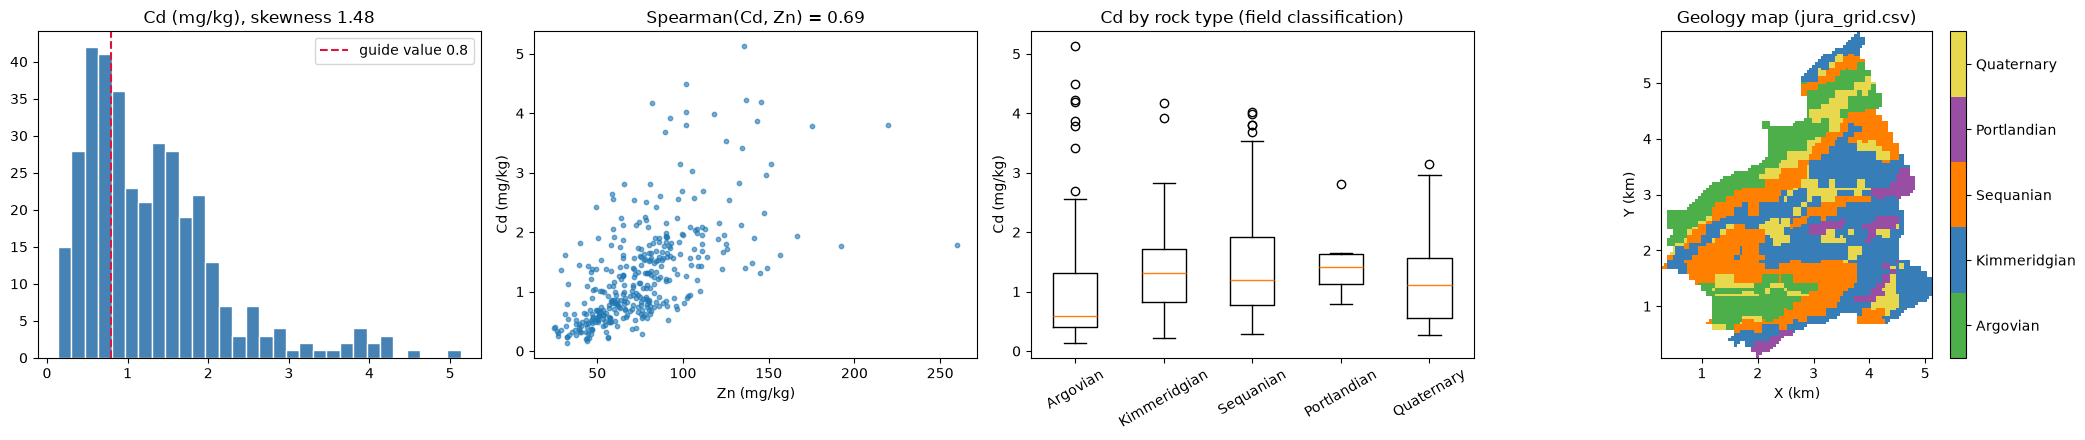

fraction of samples above 0.8 mg/kg: 0.65


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
axes[0].hist(df_all["Cd"], bins=30, color="steelblue", edgecolor="w")
axes[0].axvline(0.8, color="crimson", ls="--", label="guide value 0.8")
axes[0].set_title(f"Cd (mg/kg), skewness {df_all.Cd.skew():.2f}")
axes[0].legend()
axes[1].scatter(df_all["Zn"], df_all["Cd"], s=10, alpha=0.6)
axes[1].set_xlabel("Zn (mg/kg)")
axes[1].set_ylabel("Cd (mg/kg)")
axes[1].set_title(f"Spearman(Cd, Zn) = {df_all[['Cd', 'Zn']].corr('spearman').iloc[0, 1]:.2f}")
axes[2].boxplot([df_all.loc[df_all.Rock == c, "Cd"] for c in ROCKS])
axes[2].set_xticks(range(1, 6), list(ROCKS.values()), rotation=30)
axes[2].set_ylabel("Cd (mg/kg)")
axes[2].set_title("Cd by rock type (field classification)")
show_rock(axes[3], grid_rock, "Geology map (jura_grid.csv)")
plt.tight_layout()
plt.show()
print(f"fraction of samples above 0.8 mg/kg: {(df_all.Cd > 0.8).mean():.2f}")

### Prediction and validation sets

As in the Gaussian co-simulation notebook, 100 samples are held out at random as a **validation set** for cadmium, and the other 259 form the **prediction set**. Zinc is used at all 359 sites. This is the *undersampled* design of Goovaerts (1997): the secondary variable is known at more places than the primary.

In [5]:
rng_split = np.random.default_rng(359)
test_idx = np.sort(rng_split.choice(len(df_all), size=100, replace=False))
is_test = np.zeros(len(df_all), bool)
is_test[test_idx] = True
df = df_all[~is_test].reset_index(drop=True)
test = df_all[is_test].reset_index(drop=True)
xy, xy_test = df[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
truth = test["Cd"].to_numpy(float)
print(f"prediction set : {len(df)} sites, Cd mean {df.Cd.mean():.2f}, P(Cd > 0.8) = {(df.Cd > 0.8).mean():.2f}")
print(f"validation set : {len(test)} sites, Cd mean {test.Cd.mean():.2f}, P(Cd > 0.8) = {(test.Cd > 0.8).mean():.2f}")

prediction set : 259 sites, Cd mean 1.29, P(Cd > 0.8) = 0.65
validation set : 100 sites, Cd mean 1.28, P(Cd > 0.8) = 0.64


***
## Indicator Coding and Indicator Variograms of Cadmium

Six thresholds discretize the cadmium distribution: the 0.1, 0.25, 0.5, 0.75 and 0.9 quantiles of the prediction set, plus the guide value 0.8 mg/kg, so that $P(\text{Cd} > 0.8)$ is read directly from each simulated ccdf.

For each threshold the experimental indicator variogram is computed and a spherical model is fitted by weighted least squares. The sill is fixed at $m_k(1 - m_k)$, the variance of the indicator, so only the nugget and the range are fitted.

In [6]:
cd = df["Cd"].to_numpy(float)
THRESH = sorted(set(np.round(np.quantile(cd, [0.1, 0.25, 0.5, 0.75, 0.9]), 2).tolist()) | {0.8})
print("thresholds (mg/kg):", THRESH)


def experimental_variogram(xy, values, maxlag=2.0, n_lags=16):
    d = pdist(xy)
    g = 0.5 * pdist(values[:, None], "sqeuclidean")
    edges = np.linspace(0, maxlag, n_lags + 1)
    h, gam, npairs = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d > lo) & (d <= hi)
        h.append(d[m].mean()); gam.append(g[m].mean()); npairs.append(m.sum())
    return np.array(h), np.array(gam), np.array(npairs)


def spherical(h, nugget, a, sill):
    r = np.minimum(np.asarray(h) / a, 1.0)
    return nugget + (sill - nugget) * (1.5 * r - 0.5 * r ** 3)


def fit_indicator_vario(xy, ind):
    # spherical model with sill p(1-p); returns the GSLIB list, the experimental points
    p = ind.mean()
    sill = p * (1 - p)
    h, g, n = experimental_variogram(xy, ind)
    (nr, a), _ = curve_fit(lambda h, nr, a: spherical(h, nr * sill, a, sill), h, g, p0=[0.3, 1.0],
                           bounds=([0.0, 0.1], [0.95, 4.0]), sigma=1 / np.sqrt(n))
    return [0.0, round(nr * sill, 4), round(a, 3), round(a, 3), round(sill, 4), "spherical"], (h, g)


vario_cd, exp_cd = {}, {}
for t in THRESH:
    vario_cd[t], exp_cd[t] = fit_indicator_vario(xy, (cd <= t).astype(float))

pd.DataFrame({t: {"P(Cd<=t)": (cd <= t).mean(), "nugget": v[1], "range (km)": v[2], "sill": v[4],
                  "relative nugget": v[1] / v[4]} for t, v in vario_cd.items()}).T.round(3)

thresholds (mg/kg): [0.45, 0.68, 0.8, 1.1, 1.67, 2.34]


,P(Cd<=t),nugget,range (km),sill,relative nugget
0.45,0.108,0.057,0.930,0.096,0.593
0.68,0.247,0.092,1.005,0.186,0.497
0.80,0.347,0.138,0.908,0.227,0.610
1.10,0.502,0.214,1.080,0.250,0.856
1.67,0.749,0.167,1.417,0.188,0.890
2.34,0.900,0.048,0.208,0.090,0.528


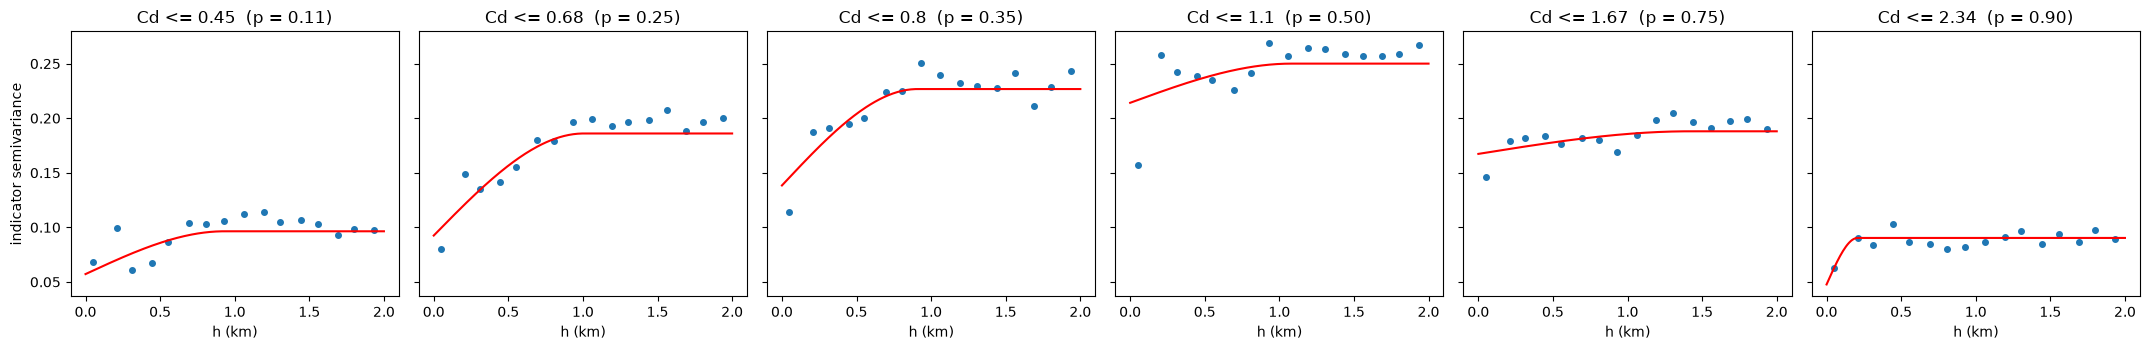

In [7]:
hh = np.linspace(0, 2.0, 200)
fig, axes = plt.subplots(1, len(THRESH), figsize=(3.6 * len(THRESH), 3.6), sharey=True)
for ax, t in zip(axes, THRESH):
    v = vario_cd[t]
    ax.plot(*exp_cd[t], "o", ms=4)
    ax.plot(hh, spherical(hh, v[1], v[2], v[4]), "r-")
    ax.set_title(f"Cd <= {t}  (p = {(cd <= t).mean():.2f})")
    ax.set_xlabel("h (km)")
axes[0].set_ylabel("indicator semivariance")
plt.tight_layout()
plt.show()

The indicator variograms differ between thresholds. The middle thresholds have the largest sills ($p \approx 0.5$). The highest threshold (the 0.9 quantile) has the shortest range, so the very high cadmium values are spatially less connected than the moderate ones. A single Gaussian variogram cannot represent that, and it is one reason to simulate cadmium through indicators.

Common settings for every run:

In [8]:
NUM_POINTS = 16
RADIUS = 1.5            # km
CONT_KW = dict(variable="continuous", num_points=NUM_POINTS, radius=RADIUS,
               zmin=0.0, zmax=6.0, ltail="linear", middle="linear", utail="hyperbolic", utpar=1.5)
PRIOR = np.array([(cd <= t).mean() for t in THRESH])   # m_k from the prediction set

***
## Soft Indicators from Zinc with `SoftCalibration`

The secondary must be known at every grid node and at the validation sites. Zinc is measured at all 359 sites, so it is ordinary-kriged onto the grid and to the validation sites (where the kriged value is close to the measured Zn, because those samples are used).

`SoftCalibration` then pairs the Cd indicators at the 259 prediction sites with the **measured** Zn there, splits Zn into 10 quantile bins, and tabulates $P(\text{Cd} \le z_k \mid \text{Zn bin})$, shrunk toward the global proportions with one pseudo-count.

Zn kriged on the grid: 26: 254 mg/kg
Markov-Bayes B per threshold: {0.45: np.float64(0.356), 0.68: np.float64(0.39), 0.8: np.float64(0.304), 1.1: np.float64(0.32), 1.67: np.float64(0.226), 2.34: np.float64(0.136)}


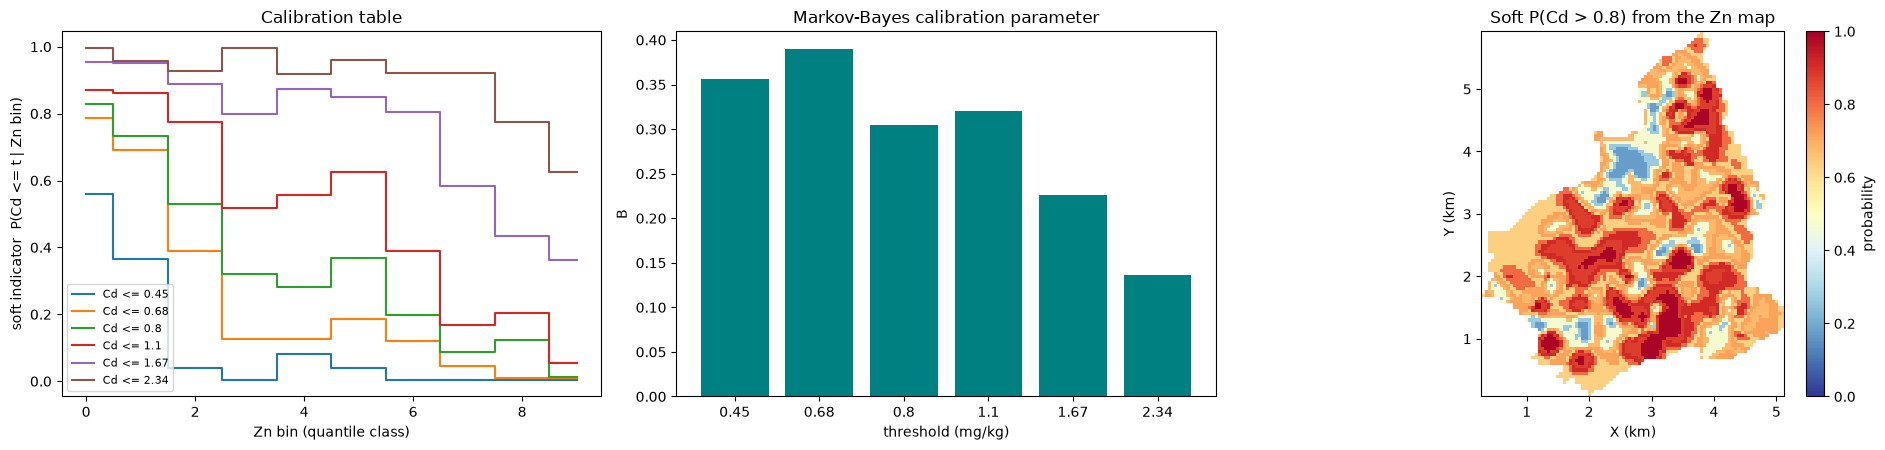

In [9]:
zn_all = df_all["Zn"].to_numpy(float)
vg_zn = Variogram(xy_all, zn_all, model="spherical", n_lags=15).fit()
ok_zn = OrdinaryKriging(vg_zn).fit(xy_all, zn_all)
zn_grid = np.asarray(ok_zn.predict(grid), float)
zn_test = np.asarray(ok_zn.predict(xy_test), float)
print(f"Zn kriged on the grid: {zn_grid.min():.0f}: {zn_grid.max():.0f} mg/kg")

ind_cd = (cd[:, None] <= np.array(THRESH)[None, :]).astype(float)
cal = SoftCalibration(n_bins=10, smoothing=1.0).fit(ind_cd, df["Zn"].to_numpy(float), prior=PRIOR)
print("Markov-Bayes B per threshold:", dict(zip(THRESH, np.round(cal.B_, 3))))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
centers = np.r_[df.Zn.min(), cal.edges_[1:-1]]
for k, t in enumerate(THRESH):
    axes[0].step(np.arange(len(cal.table_)), cal.table_[:, k], where="mid", label=f"Cd <= {t}")
axes[0].set_xlabel("Zn bin (quantile class)")
axes[0].set_ylabel("soft indicator  P(Cd <= t | Zn bin)")
axes[0].set_title("Calibration table")
axes[0].legend(fontsize=8)
axes[1].bar([str(t) for t in THRESH], cal.B_, color="teal")
axes[1].set_xlabel("threshold (mg/kg)")
axes[1].set_ylabel("B")
axes[1].set_title("Markov-Bayes calibration parameter")
soft_zn_grid = cal.transform(zn_grid)
show_map(axes[2], 1 - soft_zn_grid[:, THRESH.index(0.8)], "Soft P(Cd > 0.8) from the Zn map",
         cmap="RdYlBu_r", vmin=0, vmax=1, label="probability")
plt.tight_layout()
plt.show()

The table moves the way it should: the higher the zinc, the smaller the probability of being below a cadmium threshold. $B_k$ is around 0.3-0.4 for the middle thresholds and smaller for the extreme ones. Zinc is a useful but far from perfect predictor of cadmium, and it says least about the rare very high values.

***
## Baseline: Plain SIS with `IndicatorCoSimulator`

Without a secondary, `IndicatorCoSimulator` is plain SIS. First, the properties every conditional simulation must have, checked on a small grid made of the 259 prediction sites plus 200 random nodes:

* exact conditioning;
* variability away from the data;
* reproducibility with a fixed seed;
* identical CPU and GPU realizations.

In [10]:
pick = np.random.default_rng(0).choice(len(grid), 200, replace=False)
small_grid = np.vstack([xy, grid[pick]])

sis = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(small_grid, df, "Xloc", "Yloc", "Cd")
sims_a = sis.simulate(nsim=8, seed=11)
sims_b = sis.simulate(nsim=8, seed=11)
sims_c = sis.simulate(nsim=8, seed=12)

err = np.abs(sims_a[:, :len(df)] - cd).max()
record("SIS: exact conditioning", "PASS" if err < 1e-9 else "FAIL", f"max |sim - data| = {err:.1e}")
spread = sims_a[:, len(df):].std(axis=0).mean()
record("SIS: realizations vary away from data", "PASS" if spread > 0.1 else "FAIL",
       f"mean std across realizations = {spread:.2f} mg/kg")
record("SIS: same seed -> identical", "PASS" if np.array_equal(sims_a, sims_b) else "FAIL")
record("SIS: different seed -> different", "PASS" if not np.allclose(sims_a, sims_c) else "FAIL")

sims_cpu = IndicatorCoSimulator(THRESH, vario_cd, **CONT_KW).fit(small_grid, df, "Xloc", "Yloc", "Cd").simulate(
    nsim=8, seed=11)
diff = np.abs(sims_cpu - sims_a).max()
record("SIS: GPU = CPU for the same seed", "PASS" if diff < 1e-6 else "FAIL",
       f"max |GPU - CPU| = {diff:.1e} mg/kg" + ("" if USE_GPU else " (no GPU: both ran on CPU)"))

✅ [PASS] SIS: exact conditioning  max |sim - data| = 0.0e+00
✅ [PASS] SIS: realizations vary away from data  mean std across realizations = 0.94 mg/kg
✅ [PASS] SIS: same seed -> identical  
✅ [PASS] SIS: different seed -> different  


✅ [PASS] SIS: GPU = CPU for the same seed  max |GPU - CPU| = 2.0e-14 mg/kg


Now 100 realizations on the full grid. The pooled proportion below each threshold should be close to the input $m_k$, and the indicator variogram of the realizations close to the model.

In [11]:
N_SIM = 100
t0 = time.perf_counter()
sis_grid = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
    grid, df, "Xloc", "Yloc", "Cd").simulate(nsim=N_SIM, seed=2024)
print(f"SIS: {N_SIM} realizations x {len(grid)} nodes in {time.perf_counter() - t0:.1f} s ({'GPU' if USE_GPU else 'CPU'})")

repro = pd.DataFrame({"data m_k": PRIOR,
                      "SIS pooled": [(sis_grid <= t).mean() for t in THRESH]}, index=THRESH)
repro["difference"] = repro["SIS pooled"] - repro["data m_k"]
display(repro.round(3))
record("SIS: threshold proportions reproduced within 0.05",
       "PASS" if repro["difference"].abs().max() < 0.05 else "FAIL",
       f"max |difference| = {repro['difference'].abs().max():.3f}")

SIS: 100 realizations x 5957 nodes in 18.9 s (GPU)


,data m_k,SIS pooled,difference
0.45,0.108,0.102,-0.006
0.68,0.247,0.219,-0.028
0.80,0.347,0.329,-0.019
1.10,0.502,0.506,0.004
1.67,0.749,0.743,-0.006
2.34,0.900,0.906,0.006


✅ [PASS] SIS: threshold proportions reproduced within 0.05  max |difference| = 0.028


***
## Co-Simulation of Cadmium with `sicosim`

`sicosim` calibrates the kriged Zn map against the Cd indicators (using `secondary_col="Zn"`, the measured Zn at the data) and simulates. It builds the same calibration as the `SoftCalibration` object above, so passing those soft indicators to `IndicatorCoSimulator.fit(soft=..., soft_data=...)` gives the same realizations.

In [12]:
t0 = time.perf_counter()
cos_grid = sicosim(grid, df, "Xloc", "Yloc", "Cd", THRESH, vario_cd, secondary=zn_grid, secondary_col="Zn",
                   nsim=N_SIM, seed=2024, use_gpu=USE_GPU, **CONT_KW)
print(f"sicosim: {N_SIM} realizations x {len(grid)} nodes in {time.perf_counter() - t0:.1f} s")

soft_data_zn = cal.transform(df["Zn"].to_numpy(float))
via_soft = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
    grid, df, "Xloc", "Yloc", "Cd", soft=soft_zn_grid, soft_data=soft_data_zn).simulate(nsim=N_SIM, seed=2024)
record("sicosim(secondary=...) == fit(soft=..., soft_data=...)",
       "PASS" if np.allclose(cos_grid, via_soft) else "FAIL", f"max diff = {np.abs(cos_grid - via_soft).max():.1e}")

sicosim: 100 realizations x 5957 nodes in 21.0 s


✅ [PASS] sicosim(secondary=...) == fit(soft=..., soft_data=...)  max diff = 0.0e+00


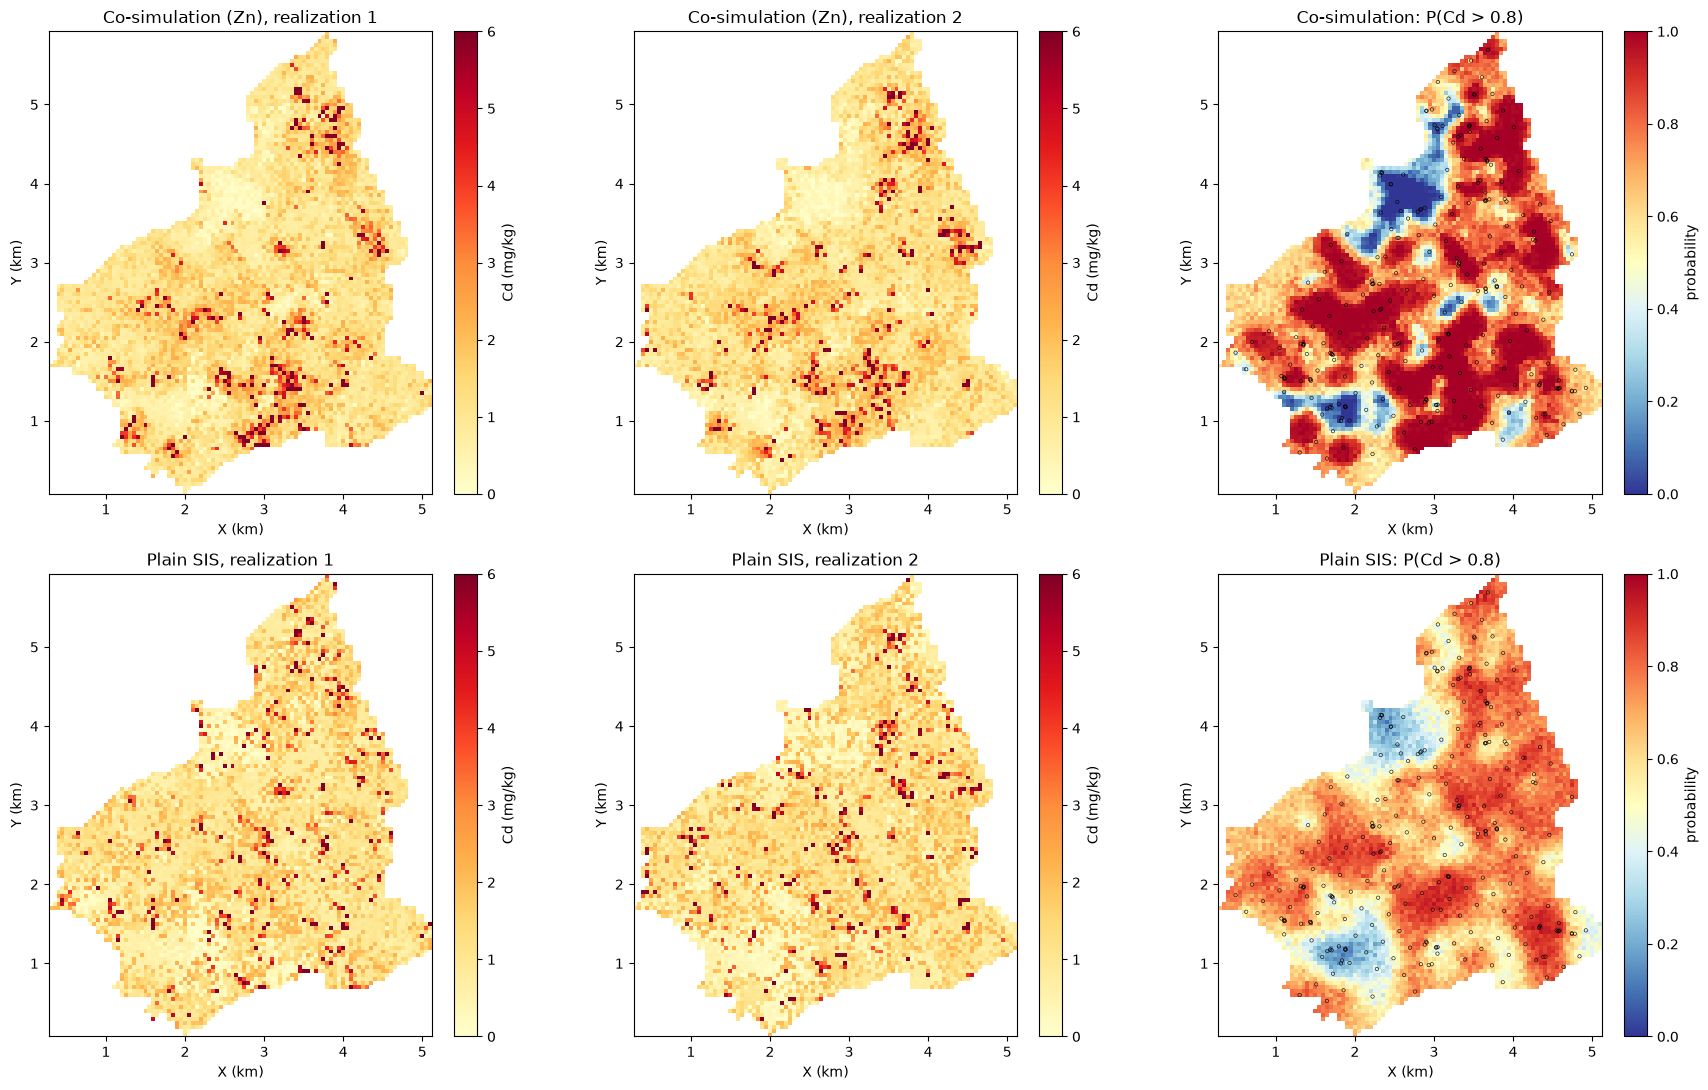

In [13]:
vmax_cd = np.percentile(np.r_[sis_grid.ravel(), cos_grid.ravel()], 99)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for j, r in enumerate([0, 1]):
    show_map(axes[0, j], cos_grid[r], f"Co-simulation (Zn), realization {r + 1}", cmap="YlOrRd", vmin=0, vmax=vmax_cd)
    show_map(axes[1, j], sis_grid[r], f"Plain SIS, realization {r + 1}", cmap="YlOrRd", vmin=0, vmax=vmax_cd)
show_map(axes[0, 2], (cos_grid > 0.8).mean(0), "Co-simulation: P(Cd > 0.8)", cmap="RdYlBu_r", vmin=0, vmax=1,
         label="probability", points=xy)
show_map(axes[1, 2], (sis_grid > 0.8).mean(0), "Plain SIS: P(Cd > 0.8)", cmap="RdYlBu_r", vmin=0, vmax=1,
         label="probability", points=xy)
plt.tight_layout()
plt.show()

The co-simulated realizations follow the zinc pattern, and the probability map of exceeding the guide value is sharper: more nodes are close to 0 or 1. Whether that sharper map is *right* is a question for the held-out data.

***
## Validation at 100 Held-Out Sites

The realizations are drawn on the grid **plus** the 100 validation sites (with their kriged Zn), and scored on the true cadmium there:

| Metric | Meaning | Better |
|---|---|---|
| RMSE of the E-type | accuracy of the mean of the realizations | lower |
| coverage of the 80% interval | fraction of true values between the 10th and 90th percentiles of the realizations | close to 0.80 |
| width of the 80% interval | sharpness | lower, if coverage holds |
| Brier score of $P(\text{Cd} > 0.8)$ | $\frac{1}{n}\sum (p_i - o_i)^2$ with $o_i = 1$ if the site exceeds 0.8 | lower |
| misclassification | fraction of sites on the wrong side of 0.8 with the rule $p > 0.5$ | lower |

The accuracy plot extends the coverage check to all symmetric probability intervals.

In [14]:
N_VAL = 300
val_grid = np.vstack([grid, xy_test])
zn_val = np.r_[zn_grid, zn_test]
VAL = slice(len(grid), None)


def score(name, ens):
    et = ens.mean(0)
    lo, hi = np.percentile(ens, [10, 90], axis=0)
    p = (ens > 0.8).mean(0)
    o = (truth > 0.8).astype(float)
    return {"method": name, "RMSE": np.sqrt(np.mean((et - truth) ** 2)),
            "cover80": np.mean((truth >= lo) & (truth <= hi)), "width80": np.mean(hi - lo),
            "Brier(0.8)": np.mean((p - o) ** 2), "misclass(0.8)": np.mean((p > 0.5) != (o > 0.5))}


def accuracy_curve(ens, ps=np.linspace(0.05, 0.95, 19)):
    return ps, [np.mean((truth >= np.percentile(ens, 50 - 50 * p, axis=0)) &
                        (truth <= np.percentile(ens, 50 + 50 * p, axis=0))) for p in ps]


def shrink(soft, f, prior=PRIOR):
    # pull soft indicators toward the prior: y_f = m + f (y - m)
    return prior + f * (soft - prior)


sis_val = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(val_grid, df, "Xloc", "Yloc", "Cd")
ens_sis = sis_val.simulate(nsim=N_VAL, seed=1)[:, VAL]

soft_val = cal.transform(zn_val)
mb_val = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
    val_grid, df, "Xloc", "Yloc", "Cd", soft=soft_val, soft_data=soft_data_zn)
ens_mb = mb_val.simulate(nsim=N_VAL, seed=1)[:, VAL]

table = pd.DataFrame([score("SIS (no soft data)", ens_sis), score("Markov-Bayes, Zn", ens_mb)]).set_index("method")
table.round(3)

,RMSE,cover80,width80,Brier(0.8),misclass(0.8)
method,,,,,
SIS (no soft data),0.721,0.88,1.999,0.153,0.22
"Markov-Bayes, Zn",0.705,0.76,1.852,0.129,0.23


The full Markov-Bayes co-simulation ($f = 1$) improves the probability of exceeding the guide value (Brier score 0.153 → 0.129), and slightly improves the E-type (RMSE 0.721 → 0.705 mg/kg). But its 80% intervals are narrower (1.85 vs 2.00 mg/kg) and cover only 76% of the true values: the local distributions are **over-confident**. That is the double counting of a smooth secondary predicted in Section 2.8. The kriged Zn map is smooth, and each node uses it again on top of neighbours that already used it.

### Shrinking the soft indicators

Section 2.8 predicted that a smooth secondary is counted more than once. The remedy is to shrink the soft indicators toward the prior, $y_f = m_k + f(y - m_k)$, which also scales the calibrated $B_k$ by $f$. Scan $f$ on the validation sites:

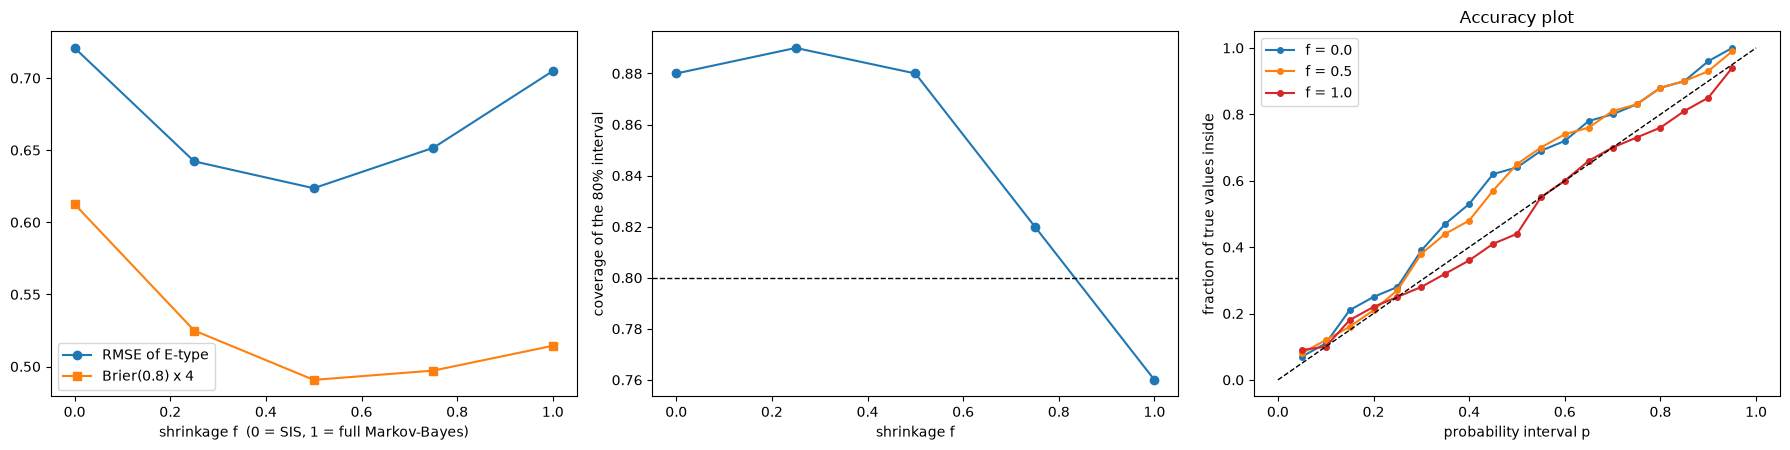

,RMSE,cover80,width80,Brier(0.8),misclass(0.8),mean B
method,,,,,,
f = 0.0,0.721,0.88,1.999,0.153,0.22,0.000
f = 0.25,0.642,0.89,2.035,0.131,0.20,0.072
f = 0.5,0.624,0.88,2.036,0.123,0.21,0.144
f = 0.75,0.652,0.82,1.948,0.124,0.22,0.217
f = 1.0,0.705,0.76,1.852,0.129,0.23,0.289


In [15]:
scan = []
ens_f = {}
for f in [0.0, 0.25, 0.5, 0.75, 1.0]:
    sim = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
        val_grid, df, "Xloc", "Yloc", "Cd", soft=shrink(soft_val, f), soft_data=shrink(soft_data_zn, f))
    ens_f[f] = sim.simulate(nsim=N_VAL, seed=1)[:, VAL]
    scan.append({**score(f"f = {f}", ens_f[f]), "mean B": sim.B_.mean()})
scan = pd.DataFrame(scan).set_index("method")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
fs = [0.0, 0.25, 0.5, 0.75, 1.0]
axes[0].plot(fs, scan["RMSE"], "o-", label="RMSE of E-type")
axes[0].plot(fs, scan["Brier(0.8)"] * 4, "s-", label="Brier(0.8) x 4")
axes[0].set_xlabel("shrinkage f  (0 = SIS, 1 = full Markov-Bayes)")
axes[0].legend()
axes[1].plot(fs, scan["cover80"], "o-")
axes[1].axhline(0.8, color="k", ls="--", lw=1)
axes[1].set_xlabel("shrinkage f")
axes[1].set_ylabel("coverage of the 80% interval")
for f, c in [(0.0, "tab:blue"), (0.5, "tab:orange"), (1.0, "tab:red")]:
    axes[2].plot(*accuracy_curve(ens_f[f]), "o-", ms=4, c=c, label=f"f = {f}")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_xlabel("probability interval p")
axes[2].set_ylabel("fraction of true values inside")
axes[2].set_title("Accuracy plot")
axes[2].legend()
plt.tight_layout()
plt.show()
scan.round(3)

In [16]:
F_ZN = 0.5
row_sis, row_f = scan.loc["f = 0.0"], scan.loc[f"f = {F_ZN}"]
record("Markov-Bayes (Zn, f=0.5) lowers RMSE vs SIS", "PASS" if row_f.RMSE < row_sis.RMSE else "FAIL",
       f"{row_sis.RMSE:.3f} -> {row_f.RMSE:.3f} mg/kg")
record("Markov-Bayes (Zn, f=0.5) lowers Brier(0.8) vs SIS",
       "PASS" if row_f["Brier(0.8)"] < row_sis["Brier(0.8)"] else "FAIL",
       f"{row_sis['Brier(0.8)']:.3f} -> {row_f['Brier(0.8)']:.3f}")
record("Markov-Bayes (Zn, f=0.5) 80% coverage in [0.70, 0.90]",
       "PASS" if 0.70 <= row_f.cover80 <= 0.90 else "FAIL", f"coverage = {row_f.cover80:.2f}")

✅ [PASS] Markov-Bayes (Zn, f=0.5) lowers RMSE vs SIS  0.721 -> 0.624 mg/kg
✅ [PASS] Markov-Bayes (Zn, f=0.5) lowers Brier(0.8) vs SIS  0.153 -> 0.123
✅ [PASS] Markov-Bayes (Zn, f=0.5) 80% coverage in [0.70, 0.90]  coverage = 0.88


Shrinking the soft indicators halfway ($f = 0.5$) gives the best result on every measure. E-type RMSE falls from 0.721 to 0.624 mg/kg (−13%) and the Brier score from 0.153 to 0.123 (−20%), while coverage stays at 0.88 with intervals as wide as SIS's. In other words, the intervals are **better placed**, not narrower. $f = 0.25$ and $f = 0.75$ are nearly as good, so the choice is not delicate; $f = 1$ overshoots. The misclassification rate at the 0.5 probability cut barely moves (0.22 → 0.21). That rule throws away most of the probability information, which the Brier score keeps.

$f = 0.5$ is used for the cadmium maps below.

***
## Soft Probabilities from the Geology Map

Geology is a **categorical** secondary known at every grid node, so it cannot go through the binning of `SoftCalibration`. Instead, the soft indicators are the conditional proportions $P(\text{Cd} \le z_k \mid \text{rock type})$ from the 259 prediction sites, and they are passed with `fit(soft=..., soft_data=...)`. `soft_data` (the same table looked up at the data) is used to estimate $B_k$.

The rock type used is the one on the **geology map** at each site (the nearest grid node), not the one recorded in the field, because the map is what is available at the grid nodes. The two agree at about 86% of the sites.

In [17]:
tree = cKDTree(grid)
map_rock_data = grid_rock[tree.query(xy)[1]]
map_rock_val = np.r_[grid_rock, grid_rock[tree.query(xy_test)[1]]]
print(f"field vs map rock type agree at {np.mean(map_rock_data == df.Rock.to_numpy()):.0%} of the prediction sites")

geo_table = pd.DataFrame({t: (df.Cd <= t).groupby(map_rock_data).mean() for t in THRESH})
geo_table.index = [ROCKS[c] for c in geo_table.index]
display(geo_table.round(2).rename_axis("P(Cd <= t | rock)"))
geo_table.index = [ROCK_CODE[c] for c in geo_table.index]

soft_geo_val = geo_table.loc[map_rock_val].to_numpy()
soft_geo_data = geo_table.loc[map_rock_data].to_numpy()

rows = []
ens_geo = {}
for f in [1.0, 0.5, 0.25]:
    sim = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
        val_grid, df, "Xloc", "Yloc", "Cd", soft=shrink(soft_geo_val, f), soft_data=shrink(soft_geo_data, f))
    ens_geo[f] = sim.simulate(nsim=N_VAL, seed=1)[:, VAL]
    rows.append({**score(f"geology, f = {f}", ens_geo[f]), "mean B": sim.B_.mean()})
    if f == 1.0:
        print("B per threshold (geology, f = 1):", dict(zip(THRESH, np.round(sim.B_, 3))))

p_geo_only = 1 - soft_geo_val[VAL, THRESH.index(0.8)]
o = (truth > 0.8).astype(float)
print(f"Brier(0.8) of the geology table alone: {np.mean((p_geo_only - o) ** 2):.3f}; "
      f"of the global proportion: {np.mean((1 - PRIOR[THRESH.index(0.8)] - o) ** 2):.3f}")
geo_scores = pd.concat([table.loc[["SIS (no soft data)"]], pd.DataFrame(rows).set_index("method")])
geo_scores.round(3)

field vs map rock type agree at 85% of the prediction sites


,0.45,0.68,0.80,1.10,1.67,2.34
P(Cd <= t | rock),,,,,,
Argovian,0.27,0.66,0.73,0.73,0.80,0.89
Kimmeridgian,0.05,0.10,0.22,0.43,0.77,0.92
Sequanian,0.07,0.15,0.29,0.46,0.67,0.86
Portlandian,0.00,0.20,0.30,0.70,0.90,0.90
Quaternary,0.15,0.28,0.32,0.45,0.77,0.94


B per threshold (geology, f = 1): {0.45: np.float64(0.073), 0.68: np.float64(0.206), 0.8: np.float64(0.136), 1.1: np.float64(0.052), 1.67: np.float64(0.018), 2.34: np.float64(0.009)}


Brier(0.8) of the geology table alone: 0.208; of the global proportion: 0.231


,RMSE,cover80,width80,Brier(0.8),misclass(0.8),mean B
method,,,,,,
SIS (no soft data),0.721,0.88,1.999,0.153,0.22,NaN
"geology, f = 1.0",0.787,0.78,1.849,0.174,0.23,0.082
"geology, f = 0.5",0.741,0.87,1.921,0.158,0.19,0.041
"geology, f = 0.25",0.728,0.87,1.979,0.153,0.22,0.021


The geology map is a weak secondary for cadmium *at this sampling density*. Its $B_k$ are small (at most 0.21, near 0 for the high thresholds). On its own the geology table is better than knowing nothing (Brier 0.208 vs 0.231 for the global proportion), but it is much worse than SIS (0.153). The 259 nearby cadmium samples already carry what geology says about cadmium.

Used as full Markov-Bayes soft data, geology **hurts**: RMSE 0.721 → 0.787, Brier 0.153 → 0.174, coverage 0.78. A geology map is piecewise constant, the extreme case of a smooth secondary, so it is double-counted the most. Shrinking brings the result back toward SIS ($f = 0.25$ matches it) but never beats it.

The lesson: soft data help only when they carry information that the hard data in the neighbourhood do not, and the only way to know is to validate.

***
## Categorical Co-Simulation: Rock Type

The same engine simulates **classes**. Here the variable is rock type at the 259 prediction sites, and the **geology map** is the reference to check against. The field classification of the samples and the map disagree at about 15% of the sites, so perfect agreement with the map is not expected.

The soft secondary is cobalt. Its concentration depends on the parent rock (soils on Argovian rocks are clearly poorer in Co), and a kriged Co map from all 359 sites gives soft class probabilities through `SoftCalibration`.

The indicator variogram of each class is fitted as before, with sill $p_k(1 - p_k)$. `classes=[1, 2, 3, 4, 5]` and `variable="categorical"`. Portlandian has only a few samples, so its variogram and proportion are poorly known.

In [18]:
CLASSES = [1, 2, 3, 4, 5]
rock = df["Rock"].to_numpy(float)
vario_rock = {c: fit_indicator_vario(xy, (rock == c).astype(float))[0] for c in CLASSES}
print(pd.DataFrame({ROCKS[c]: {"proportion": (rock == c).mean(), "nugget": v[1], "range (km)": v[2], "sill": v[4]}
                    for c, v in vario_rock.items()}).T.round(3))

co_all = df_all["Co"].to_numpy(float)
vg_co = Variogram(xy_all, co_all, model="spherical", n_lags=15).fit()
co_grid = np.asarray(OrdinaryKriging(vg_co).fit(xy_all, co_all).predict(grid), float)

rock_sis = IndicatorCoSimulator(CLASSES, vario_rock, num_points=NUM_POINTS, radius=RADIUS, use_gpu=USE_GPU)
rock_sis.fit(grid, df, "Xloc", "Yloc", "Rock")
rock_co = IndicatorCoSimulator(CLASSES, vario_rock, num_points=NUM_POINTS, radius=RADIUS, use_gpu=USE_GPU)
rock_co.fit(grid, df, "Xloc", "Yloc", "Rock", secondary=co_grid, secondary_col="Co")
print("B per class (Co):", {ROCKS[c]: round(b, 3) for c, b in zip(CLASSES, rock_co.B_)})

prior_rock = rock_co.proportions_
soft_co_data = rock_co.calibration_.transform(df["Co"].to_numpy(float))
rock_co_half = IndicatorCoSimulator(CLASSES, vario_rock, num_points=NUM_POINTS, radius=RADIUS, use_gpu=USE_GPU)
rock_co_half.fit(grid, df, "Xloc", "Yloc", "Rock", soft=shrink(rock_co.soft_, 0.5, prior_rock),
                 soft_data=shrink(soft_co_data, 0.5, prior_rock))

reals = {"SIS": rock_sis.simulate(nsim=N_SIM, seed=5), "Co, f = 1": rock_co.simulate(nsim=N_SIM, seed=5),
         "Co, f = 0.5": rock_co_half.simulate(nsim=N_SIM, seed=5)}


def class_summary(r):
    counts = np.stack([(r == c).mean(0) for c in CLASSES])      # (K, n_nodes) class frequencies
    mode = np.array(CLASSES)[counts.argmax(0)]
    return counts, mode


rows = []
for name, r in reals.items():
    counts, mode = class_summary(r)
    rows.append({"method": name, "agreement (most probable class)": np.mean(mode == grid_rock),
                 "agreement (per realization)": np.mean(r == grid_rock),
                 **{f"prop. {ROCKS[c]}": np.mean(r == c) for c in CLASSES}})
rows.append({"method": "geology map", "agreement (most probable class)": 1.0, "agreement (per realization)": 1.0,
             **{f"prop. {ROCKS[c]}": np.mean(grid_rock == c) for c in CLASSES}})
rows.append({"method": "samples (259)", **{f"prop. {ROCKS[c]}": np.mean(rock == c) for c in CLASSES}})
rock_table = pd.DataFrame(rows).set_index("method")
rock_table.round(3)

              proportion  nugget  range (km)   sill
Argovian           0.208   0.029       1.189  0.165
Kimmeridgian       0.363   0.078       1.346  0.231
Sequanian          0.259   0.000       0.568  0.192
Portlandian        0.012   0.000       0.363  0.011
Quaternary         0.158   0.000       0.378  0.133


B per class (Co): {'Argovian': np.float64(0.409), 'Kimmeridgian': np.float64(0.136), 'Sequanian': np.float64(0.109), 'Portlandian': np.float64(0.026), 'Quaternary': np.float64(0.043)}


,agreement (most probable class),agreement (per realization),prop. Argovian,prop. Kimmeridgian,prop. Sequanian,prop. Portlandian,prop. Quaternary
method,,,,,,,
SIS,0.696,0.575,0.206,0.444,0.217,0.015,0.118
"Co, f = 1",0.670,0.548,0.190,0.446,0.241,0.018,0.105
"Co, f = 0.5",0.689,0.565,0.199,0.448,0.227,0.016,0.110
geology map,1.000,1.000,0.199,0.342,0.273,0.053,0.133
samples (259),NaN,NaN,0.208,0.363,0.259,0.012,0.158


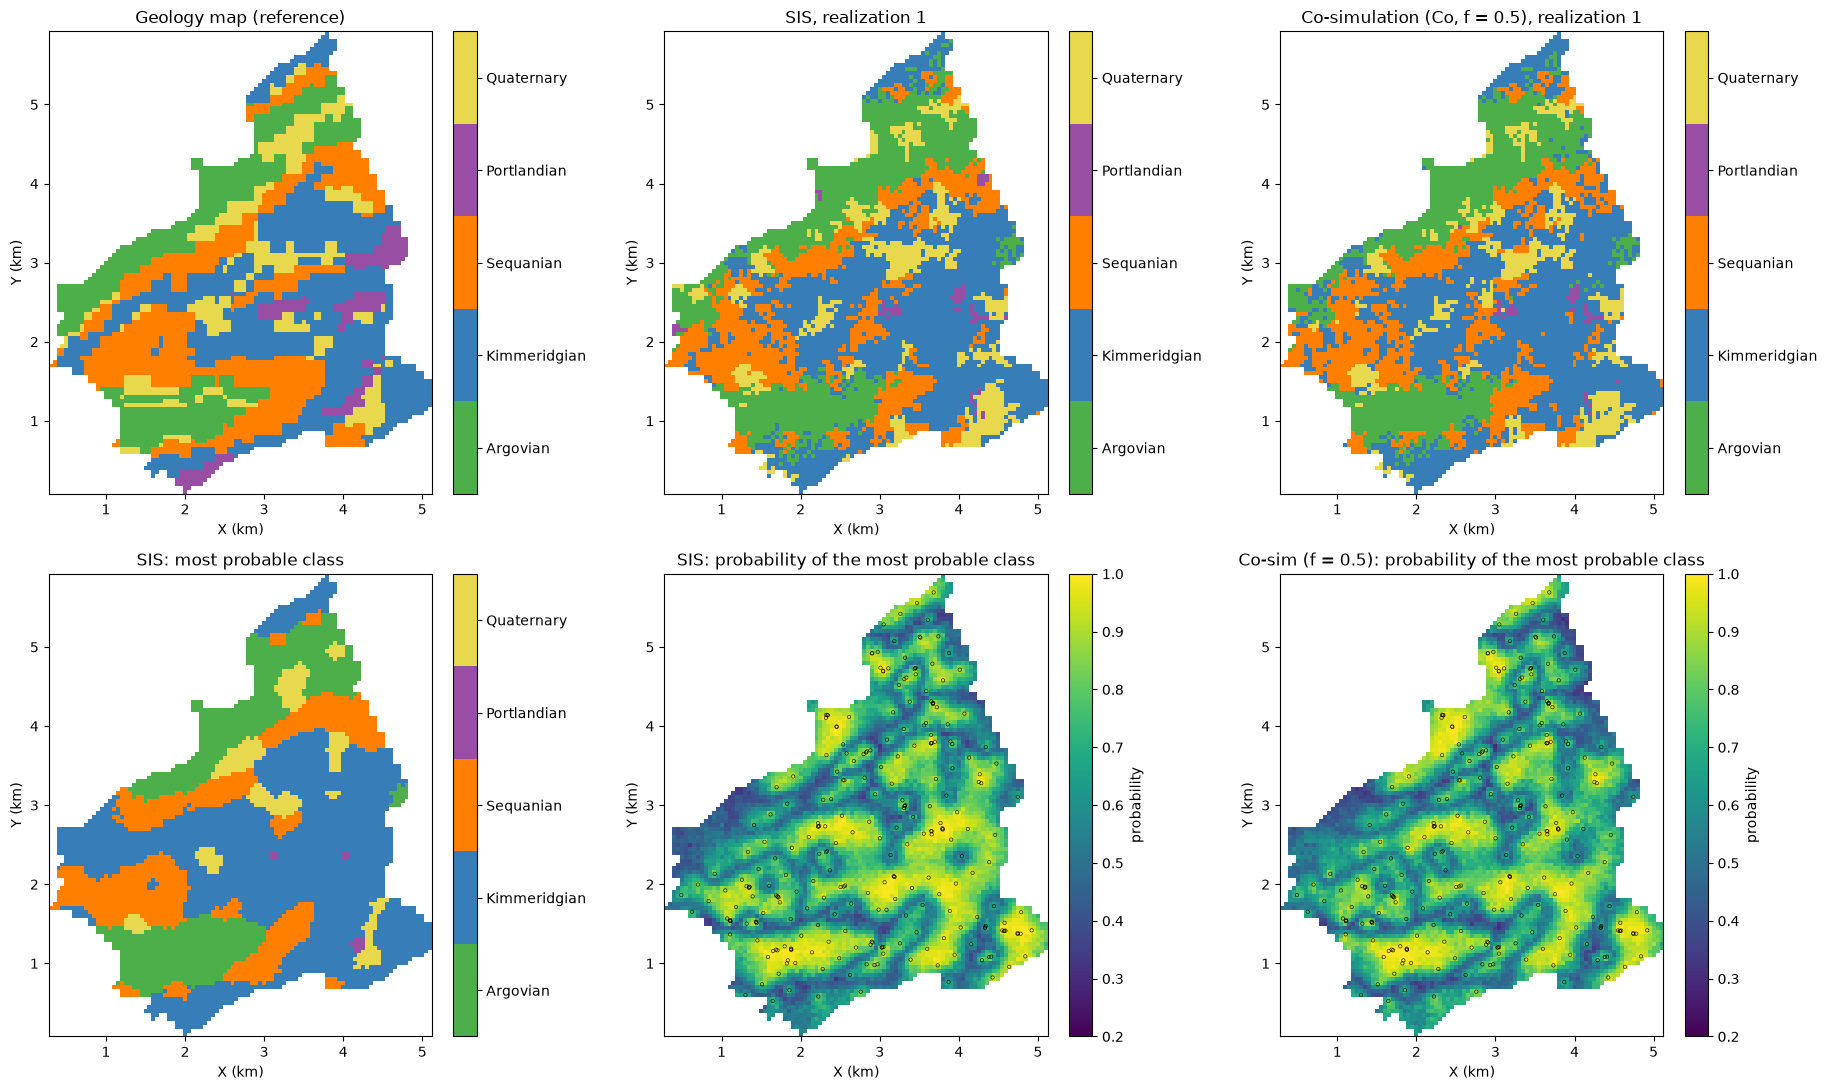

✅ [PASS] categorical co-simulation: exact conditioning  rock type at the 259 data sites reproduced in every realization


In [19]:
counts_sis, mode_sis = class_summary(reals["SIS"])
counts_co, mode_co = class_summary(reals["Co, f = 0.5"])
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
show_rock(axes[0, 0], grid_rock, "Geology map (reference)")
show_rock(axes[0, 1], reals["SIS"][0], "SIS, realization 1")
show_rock(axes[0, 2], reals["Co, f = 0.5"][0], "Co-simulation (Co, f = 0.5), realization 1")
show_rock(axes[1, 0], mode_sis, "SIS: most probable class")
show_map(axes[1, 1], counts_sis.max(0), "SIS: probability of the most probable class", cmap="viridis",
         vmin=0.2, vmax=1, label="probability", points=xy)
show_map(axes[1, 2], counts_co.max(0), "Co-sim (f = 0.5): probability of the most probable class",
         cmap="viridis", vmin=0.2, vmax=1, label="probability", points=xy)
plt.tight_layout()
plt.show()

chk = IndicatorCoSimulator(CLASSES, vario_rock, num_points=NUM_POINTS, radius=RADIUS, use_gpu=USE_GPU).fit(
    small_grid, df, "Xloc", "Yloc", "Rock", soft=shrink(rock_co.calibration_.transform(np.r_[df.Co.to_numpy(float),
    co_grid[pick]]), 0.5, prior_rock), soft_data=shrink(soft_co_data, 0.5, prior_rock)).simulate(nsim=5, seed=1)
record("categorical co-simulation: exact conditioning", "PASS" if np.array_equal(chk[:, :len(df)], np.tile(rock, (5, 1)))
       else "FAIL", "rock type at the 259 data sites reproduced in every realization")

* **Agreement with the map.** The most probable class from SIS matches the geology map at 70% of the nodes; individual realizations match at 57-58%, as they should, since a realization is a plausible map, not the most likely one. Cobalt mainly identifies the **Argovian** unit ($B = 0.41$; at most 0.14 for the others). As full soft data it lowers the agreement (0.67), and shrunk ($f = 0.5$) it is about level with SIS (0.69). The pattern is the same as for cadmium with geology: a smooth kriged map that adds little beyond 259 nearby class observations.
* **Realizations** have patchy, map-like units that honour the samples. The probability of the most probable class is high near the samples and low along unit boundaries, which is where the uncertainty is.
* **Class proportions are not reproduced exactly.** Kimmeridgian is over-produced (0.44 against 0.36 in the samples) at the expense of Sequanian and Quaternary. Kimmeridgian has the longest indicator range (1.35 km), so its kriged probabilities stay high far from the data, and clipping and renormalizing them favours it. Portlandian, with 3 samples, comes out at 1.5% against 5.3% on the map: a class that is barely sampled cannot be recovered. Categorical SIS controls proportions only through the kriging means $m_k$. When target proportions matter, check them on the realizations, as here, and consider declustered `proportions` or a method that enforces them (e.g. [simulated annealing](05_07_00_introduction_geostatistical_sumulations.ipynb)).

***
## Visualization of Spatial Uncertainty

The cadmium realizations from the shrunk Zn co-simulation ($f = 0.5$), drawn on the full grid, are used to map uncertainty: an animation of realizations, conditional quantile maps, and the probability of exceeding the guide value with the uncertainty of the contaminated area.

In [20]:
best = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=USE_GPU, **CONT_KW).fit(
    grid, df, "Xloc", "Yloc", "Cd", soft=shrink(soft_zn_grid, F_ZN), soft_data=shrink(soft_data_zn, F_ZN))
cos_f = best.simulate(nsim=N_SIM, seed=2024)
print(f"{cos_f.shape[0]} realizations, B = {np.round(best.B_, 3)}")

100 realizations, B = [0.178 0.195 0.152 0.16  0.113 0.068]


### Animated display of realizations

The first 20 realizations in sequence, on one colour scale. Areas that keep their colour are well constrained by the Cd data and the zinc map; areas that flicker are not.

In [21]:
N_FRAMES = 20
plt.rcParams["animation.embed_limit"] = 50
fig_anim, ax_anim = plt.subplots(figsize=(7.2, 7.6))
im_anim = ax_anim.imshow(to_image(cos_f[0]), origin="lower", extent=EXTENT, cmap="YlOrRd", vmin=0, vmax=vmax_cd)
ax_anim.scatter(xy[:, 0], xy[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
plt.colorbar(im_anim, ax=ax_anim, label="Cd (mg/kg)", fraction=0.046, pad=0.04)
ax_anim.set_xlabel("X (km)")
ax_anim.set_ylabel("Y (km)")
title_anim = ax_anim.set_title(f"Co-simulated Cd, realization 1 / {N_FRAMES}")


def _update(frame):
    im_anim.set_data(to_image(cos_f[frame]))
    title_anim.set_text(f"Co-simulated Cd, realization {frame + 1} / {N_FRAMES}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_FRAMES, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Conditional quantile maps (q10, median, q90)

At each node, the 0.10, 0.50 and 0.90 quantiles of the simulated values. A high q10 marks areas where cadmium is *certainly high*, and a low q90 marks areas where it is *certainly low* (Goovaerts, 1997).

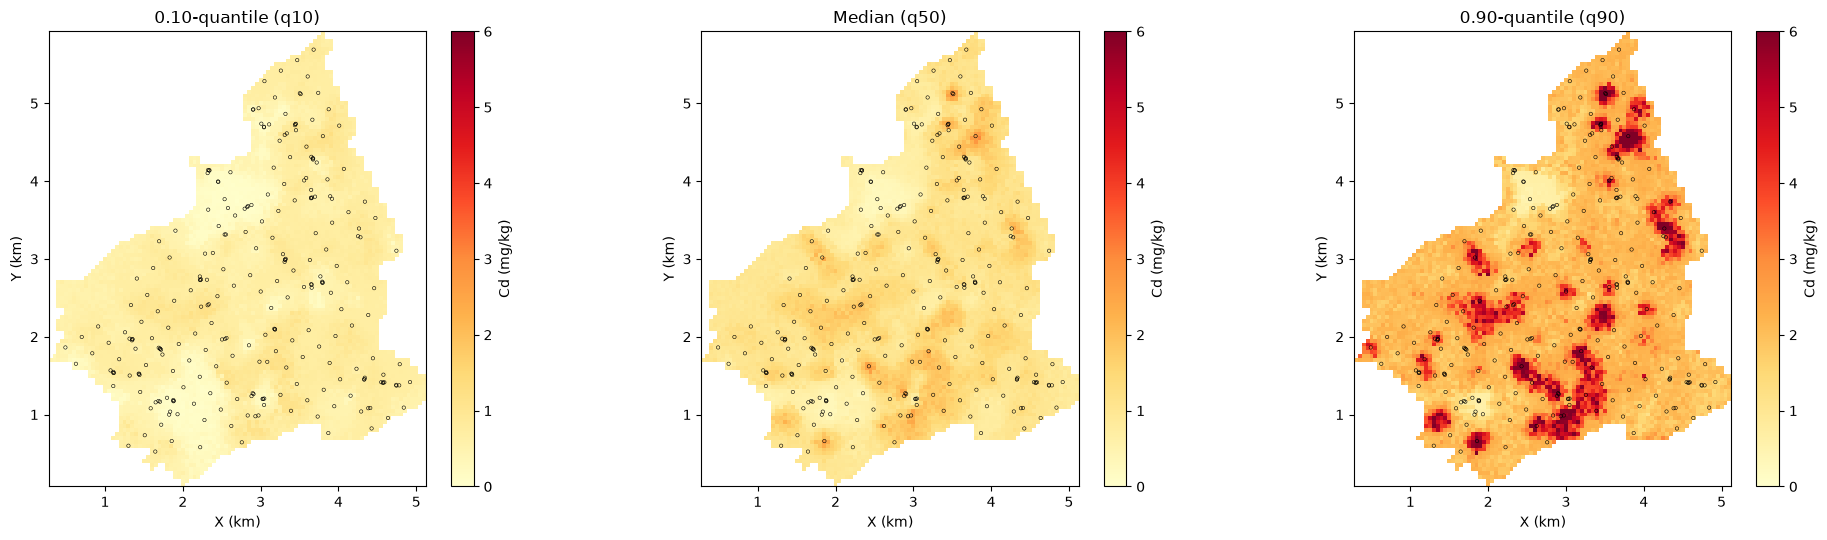

mean width of the 80% interval: co-simulation 1.79 mg/kg, SIS 1.92 mg/kg


In [22]:
q10, q50, q90 = np.quantile(cos_f, [0.10, 0.50, 0.90], axis=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, vals, title in zip(axes, (q10, q50, q90), ("0.10-quantile (q10)", "Median (q50)", "0.90-quantile (q90)")):
    show_map(ax, vals, title, cmap="YlOrRd", vmin=0, vmax=vmax_cd, points=xy)
plt.tight_layout()
plt.show()
q10s, q90s = np.quantile(sis_grid, [0.10, 0.90], axis=0)
print(f"mean width of the 80% interval: co-simulation {np.mean(q90 - q10):.2f} mg/kg, SIS {np.mean(q90s - q10s):.2f} mg/kg")

### Probability of exceeding the guide value

$\Pr\{\text{Cd}(\mathbf{u}) > 0.8\}$ is the fraction of realizations above 0.8 mg/kg. Classifying nodes as contaminated when that probability exceeds 0.5 gives one map. The realizations also give a distribution for the contaminated **area**, which a single kriging map cannot.

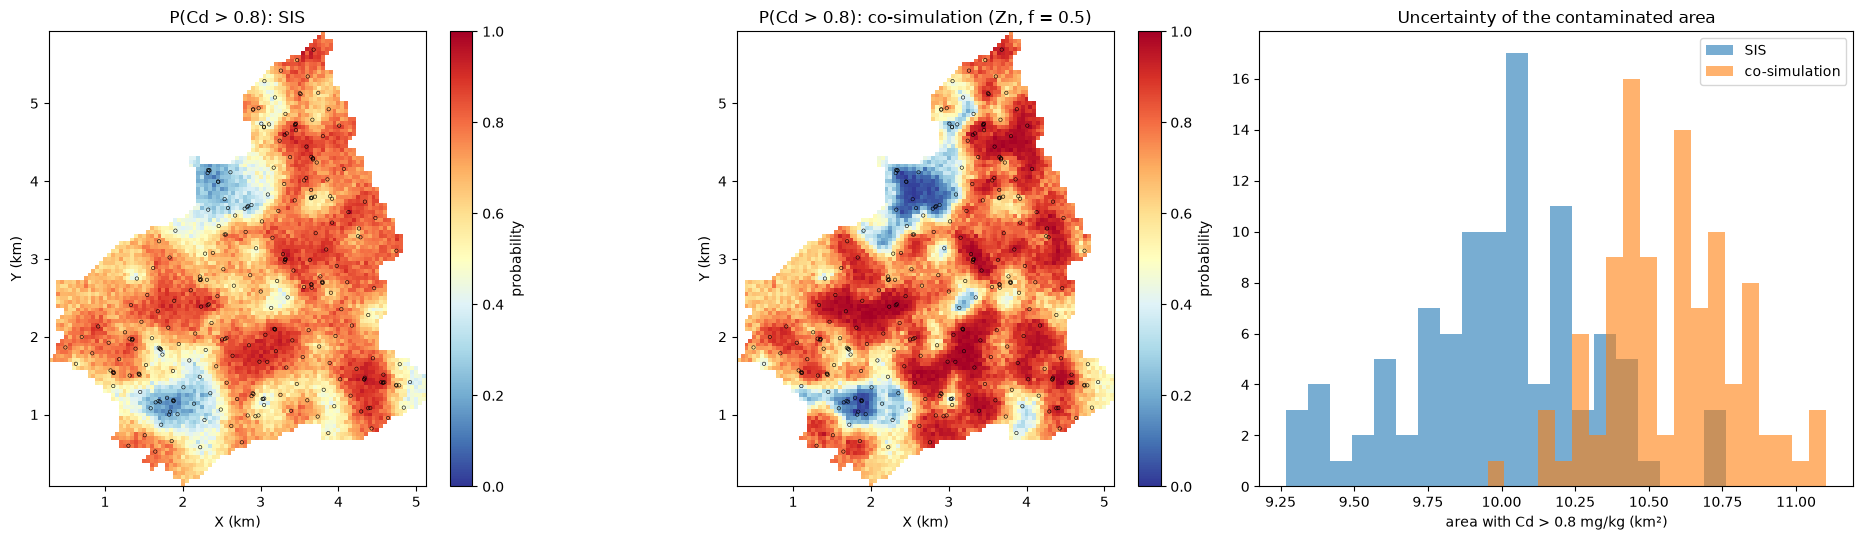

SIS           : area 9.99 km² (80% interval 9.59-10.38); nodes with P < 0.1 or P > 0.9: 2%
co-simulation : area 10.57 km² (80% interval 10.28-10.86); nodes with P < 0.1 or P > 0.9: 20%


In [23]:
p_sis, p_cos = (sis_grid > 0.8).mean(0), (cos_f > 0.8).mean(0)
area_sis = (sis_grid > 0.8).sum(1) * CELL ** 2
area_cos = (cos_f > 0.8).sum(1) * CELL ** 2
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_map(axes[0], p_sis, "P(Cd > 0.8): SIS", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability", points=xy)
show_map(axes[1], p_cos, "P(Cd > 0.8): co-simulation (Zn, f = 0.5)", cmap="RdYlBu_r", vmin=0, vmax=1,
         label="probability", points=xy)
axes[2].hist(area_sis, bins=20, alpha=0.6, label="SIS")
axes[2].hist(area_cos, bins=20, alpha=0.6, label="co-simulation")
axes[2].set_xlabel("area with Cd > 0.8 mg/kg (km²)")
axes[2].set_title("Uncertainty of the contaminated area")
axes[2].legend()
plt.tight_layout()
plt.show()
for name, a, p in [("SIS", area_sis, p_sis), ("co-simulation", area_cos, p_cos)]:
    print(f"{name:14s}: area {a.mean():.2f} km² (80% interval {np.quantile(a, .1):.2f}-{np.quantile(a, .9):.2f}); "
          f"nodes with P < 0.1 or P > 0.9: {np.mean((p < 0.1) | (p > 0.9)):.0%}")

***
## CPU vs GPU Timing

Continuous co-simulation of cadmium (six thresholds, Zn soft data) on the full 5,957-node grid, timed for several `nsim` on each engine, after a one-realization GPU warm-up. CPU and GPU realizations are compared for each `nsim`. Without a usable GPU, the GPU columns stay empty.

 nsim CPU (s) GPU (s) speedup max |GPU-CPU|
    1    1.97   11.18    0.2x       3.5e-14
    8   15.61   12.04    1.3x       1.1e-13
   32   63.40   18.46    3.4x       4.9e-13
   64  125.82   21.21    5.9x       4.9e-13


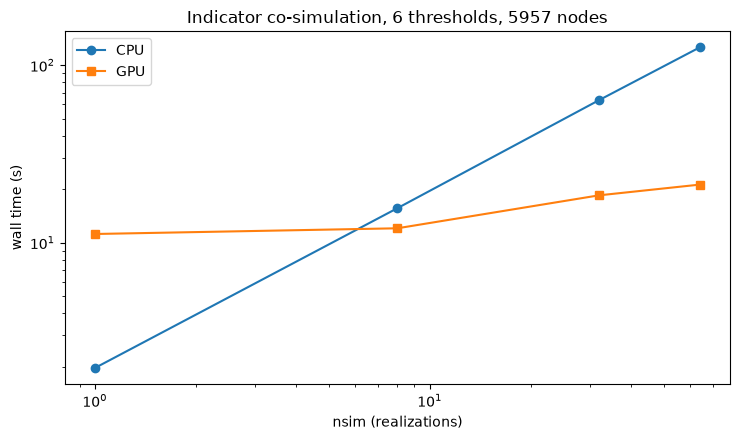

✅ [PASS] GPU indicator co-simulation equals CPU (all nsim)  max diff 4.9e-13; speedup at nsim=64: 5.9x


In [24]:
NSIM_LIST = [1, 8, 32, 64]
fit_kw = dict(soft=shrink(soft_zn_grid, F_ZN), soft_data=shrink(soft_data_zn, F_ZN))
cpu_sim = IndicatorCoSimulator(THRESH, vario_cd, use_gpu=False, **CONT_KW).fit(grid, df, "Xloc", "Yloc", "Cd", **fit_kw)
gpu_sim = (IndicatorCoSimulator(THRESH, vario_cd, use_gpu=True, **CONT_KW).fit(grid, df, "Xloc", "Yloc", "Cd", **fit_kw)
           if USE_GPU else None)
if USE_GPU:
    gpu_sim.simulate(nsim=1, seed=0)
    cp.cuda.Device(0).synchronize()

rows = []
for nsim in NSIM_LIST:
    t0 = time.perf_counter()
    out_cpu = cpu_sim.simulate(nsim=nsim, seed=5)
    row = {"nsim": nsim, "CPU (s)": time.perf_counter() - t0, "GPU (s)": np.nan, "speedup": np.nan,
           "max |GPU-CPU|": np.nan}
    if USE_GPU:
        t0 = time.perf_counter()
        out_gpu = gpu_sim.simulate(nsim=nsim, seed=5)
        cp.cuda.Device(0).synchronize()
        row["GPU (s)"] = time.perf_counter() - t0
        row["speedup"] = row["CPU (s)"] / row["GPU (s)"]
        row["max |GPU-CPU|"] = float(np.abs(out_gpu - out_cpu).max())
    rows.append(row)
bench = pd.DataFrame(rows)
print(bench.to_string(index=False, formatters={"CPU (s)": "{:.2f}".format, "GPU (s)": "{:.2f}".format,
                                               "speedup": "{:.1f}x".format, "max |GPU-CPU|": "{:.1e}".format}))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(bench["nsim"], bench["CPU (s)"], "o-", label="CPU")
if USE_GPU:
    ax.loglog(bench["nsim"], bench["GPU (s)"], "s-", label="GPU")
ax.set_xlabel("nsim (realizations)")
ax.set_ylabel("wall time (s)")
ax.set_title(f"Indicator co-simulation, {len(THRESH)} thresholds, {len(grid)} nodes")
ax.legend()
plt.tight_layout()
plt.show()
if USE_GPU:
    record("GPU indicator co-simulation equals CPU (all nsim)",
           "PASS" if bench["max |GPU-CPU|"].max() < 1e-6 else "FAIL",
           f"max diff {bench['max |GPU-CPU|'].max():.1e}; speedup at nsim={NSIM_LIST[-1]}: {bench['speedup'].iloc[-1]:.1f}x")

On this run (RTX A5500 Laptop GPU; numbers will vary):

* The CPU engine needs about 2 s per realization, because it solves six cokriging systems at every node. Its time grows linearly with `nsim` (125 s for 64).
* The GPU needs about 11 s for one realization: a single thread does all the sequential work while the rest of the GPU idles. Its time then grows slowly (21.5 s for 64). The two engines break even near `nsim = 8`, and at `nsim = 64` the GPU is about 6× faster.
* CPU and GPU realizations agree to about $10^{-13}$ mg/kg at every `nsim`.

Use the GPU for tens of realizations or more; use the CPU for one or a few.

***
## Summary and Conclusions

In [25]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,SIS: exact conditioning,PASS,max |sim - data| = 0.0e+00
1,SIS: realizations vary away from data,PASS,mean std across realizations = 0.94 mg/kg
2,SIS: same seed -> identical,PASS,
3,SIS: different seed -> different,PASS,
4,SIS: GPU = CPU for the same seed,PASS,max |GPU - CPU| = 2.0e-14 mg/kg
5,SIS: threshold proportions reproduced within 0.05,PASS,max |difference| = 0.028
6,"sicosim(secondary=...) == fit(soft=..., soft_d...",PASS,max diff = 0.0e+00
7,"Markov-Bayes (Zn, f=0.5) lowers RMSE vs SIS",PASS,0.721 -> 0.624 mg/kg
8,"Markov-Bayes (Zn, f=0.5) lowers Brier(0.8) vs SIS",PASS,0.153 -> 0.123
9,"Markov-Bayes (Zn, f=0.5) 80% coverage in [0.70...",PASS,coverage = 0.88


- **Sequential indicator (co-)simulation** kriges the probability of every class or threshold at each node and draws from the corrected distribution. It handles categorical variables and skewed continuous ones, with one variogram per class or threshold and no Gaussian assumption. On cadmium it reproduced the six threshold proportions within 0.03 and honoured the data exactly. The GPU and CPU engines agree to about $10^{-13}$.
- **Soft data** enter through **Markov-Bayes** collocated indicator cokriging. `SoftCalibration` turns a continuous secondary (kriged Zn) into soft indicators and calibration parameters $B_k$. `fit(soft=..., soft_data=...)` takes any probabilities, such as those from a geology map.
- **The Markov-Bayes co-simulation is approximate.** With a smooth secondary the collocated system counts the soft information more than once (Section 2.8). On held-out cadmium the full model sharpened the exceedance probabilities but under-covered (76% for an 80% interval).
- **Shrinking the soft indicators** halfway toward the prior fixed that. Co-simulation with zinc then beat plain SIS on every measure: E-type RMSE −13%, Brier score of $P(\text{Cd} > 0.8)$ −20%, coverage 0.88. It also made the contamination map far more decisive: 20% of nodes with $P < 0.1$ or $P > 0.9$, against 2% for SIS.
- **Not every secondary helps.** Geology for cadmium and cobalt for rock type carried little that the nearby hard data did not already have. Both hurt as full soft data and at best matched SIS when shrunk. Validate soft data before relying on them.
- **Categorical SIS** produced realistic geology-like realizations (70% agreement of the most probable class with the map) but did not hold the class proportions exactly: the long-range class grew and a barely sampled class vanished.

| Object | Role in this notebook |
|---|---|
| `IndicatorCoSimulator` | Continuous (Cd, six thresholds) and categorical (rock type) simulation; `fit(secondary=...)` or `fit(soft=..., soft_data=...)`; CPU or GPU |
| `sicosim` | One-call co-simulation of Cd with the kriged Zn map |
| `SoftCalibration` | Zn → soft indicators $P(\text{Cd} \le z_k \mid \text{Zn})$ and Markov-Bayes $B_k$ |
| `shrink` (notebook helper) | $y_f = m_k + f(y - m_k)$, the remedy for a smooth secondary |
| `Variogram` / `OrdinaryKriging` | Kriged Zn and Co maps used as secondaries |

### Choosing the options

| Situation | Choice |
|---|---|
| Continuous secondary at every node | `sicosim(..., secondary=..., secondary_col=...)` or `SoftCalibration` + `fit(soft=...)` |
| Categorical secondary (geology, land cover) or probabilities from a classifier | `fit(soft=..., soft_data=...)` or `fit(soft=..., B=...)` |
| Smooth secondary (kriged map, geology, classified image) | shrink the soft indicators ($f \approx 0.5$ here) and choose $f$ by validation |
| No secondary | `sicosim(..., secondary=None)` or `IndicatorCoSimulator(...).fit(...)`: plain SIS |
| Skewed continuous variable | thresholds at quantiles plus decision values; hyperbolic upper tail (`utail="hyperbolic"`) |
| Many realizations, GPU available | `use_gpu=True`: same realizations, faster at large `nsim` |

***
## References

| Reference | Used for |
|---|---|
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Indicator approach, Jura case study, undersampled design, quantile and probability maps |
| Journel, A.G. (1983). Nonparametric estimation of spatial distributions. *Mathematical Geology* 15, 445-468. | Indicator kriging |
| Alabert, F. (1987). *Stochastic imaging of spatial distributions using hard and soft information*. MSc thesis, Stanford University. | Sequential indicator simulation |
| Zhu, H. & Journel, A.G. (1993). Formatting and integrating soft data: stochastic imaging via the Markov-Bayes algorithm. In Soares, A. (ed.), *Geostatistics Tróia '92*, 1-12. Kluwer. | Markov-Bayes model, calibration parameter $B$ |
| Deutsch, C.V. & Journel, A.G. (1998). *GSLIB: Geostatistical Software Library and User's Guide*, 2nd ed. Oxford University Press. | `sisim`, `ordrel`, tail models, soft data option |
| Deutsch, C.V. (1997). Direct assessment of local accuracy and precision. In Baafi, E.Y. & Schofield, N.A. (eds.), *Geostatistics Wollongong '96*, 115-125. Kluwer. | Accuracy plot |
| Brier, G.W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review* 78, 1-3. | Brier score |